## Nominal Logistic Regression in Practice: Which Product Does a Client Choose?
---

### 1. Business Problem

A bank's **Marketing team** asks: **given what we know about a client, which product is he or she most likely to take: a card, a personal loan or a mortgage - and what drives that choice?**

The response, `tipo_producto`, has **3 categories with no natural order**: no product is "higher" or "lower" than another. That makes it a **nominal** response. Binary logistic regression no longer applies, because there is no longer a single 0/1 outcome.

### 2. The Data

`clientes_multicategoria.csv` has one row per client.

| Column | Type | Description |
|---|---|---|
| `id_cliente` | ID | Client identifier |
| `ingreso_mensual` | Numeric | Monthly income, in **thousands** of MXN |
| `edad_cliente` | Numeric | Client age |
| `score_buro` | Numeric | Credit bureau score |
| `estado_civil` | Categorical | Casado (**reference**) / Soltero / Divorciado |
| `tipo_producto` | **Target** (nominal) | Card / Personal loan / Mortgage |
| `historial_pagos` | Another response (ordered) | Used in Part 2. **It is not a predictor here.** |

The model uses just four predictors: `ingreso_mensual`, `edad_cliente`, `score_buro` and `estado_civil`.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_auc_score

plt.rcParams['figure.figsize'] = (8, 5)

df = pd.read_csv('clientes_multicategoria.csv')
df.head()

,id_cliente,ingreso_mensual,edad_cliente,score_buro,estado_civil,tipo_producto,historial_pagos
0,CL-0001,8.0,53,756,Casado,Mortgage,Bueno
1,CL-0002,20.5,52,619,Divorciado,Personal loan,Malo
2,CL-0003,8.0,39,721,Casado,Personal loan,Regular
3,CL-0004,18.0,21,714,Divorciado,Personal loan,Regular
4,CL-0005,38.9,58,638,Soltero,Card,Regular


### 3. Data Quality Review

We are told the data is clean, let's verify it before using it.

In [9]:
print('Shape:', df.shape)
print('Missing values:', df.isna().sum().sum())
print('Duplicate IDs:', df['id_cliente'].duplicated().sum())
df.describe().round(1).T

Shape: (1000, 7)
Missing values: 0
Duplicate IDs: 0


,count,mean,std,min,25%,50%,75%,max
ingreso_mensual,1000.0,29.9,14.9,8.0,19.1,27.4,38.9,98.9
edad_cliente,1000.0,43.3,12.9,21.0,32.0,43.0,54.0,65.0
score_buro,1000.0,682.5,54.4,450.0,645.0,684.0,720.0,850.0


Clean: no missing values, no duplicate IDs, and the ranges are sensible (income between about $8k and $99k per month, ages 21–65, bureau scores 450–850).

### 4. Setting Up the Categories

Same pattern as in the earlier notebooks: the **first category in each list is the reference**. Here that is Card for the response and Casado for `estado_civil`. Fixing the order now also makes the charts follow it.

In [10]:
product_order = ['Card', 'Personal loan', 'Mortgage']          # reference first
df['tipo_producto'] = pd.Categorical(df['tipo_producto'], categories=product_order)
df['estado_civil'] = pd.Categorical(df['estado_civil'], categories=['Casado', 'Soltero', 'Divorciado'])

### 5. Exploring the Response

tipo_producto
Card             0.385
Personal loan    0.318
Mortgage         0.297
Name: proportion, dtype: float64


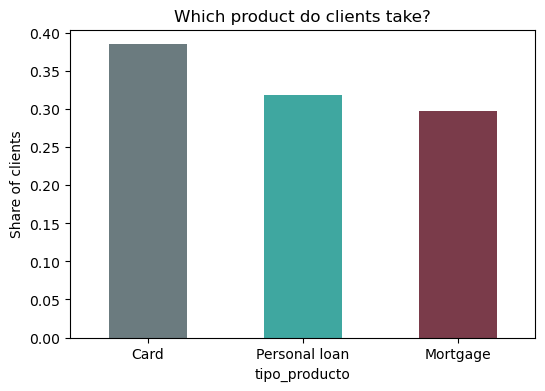

In [11]:
shares = df['tipo_producto'].value_counts(normalize=True).reindex(product_order)
print(shares.round(3))

ax = shares.plot(kind='bar', color=['#6B7B7F', '#3FA7A0', '#7A3B4A'], rot=0, figsize=(6, 4))
ax.set_ylabel('Share of clients')
ax.set_title('Which product do clients take?')
plt.show()

**Interpretation:** the three products are reasonably balanced, Card 38.5%, Personal loan 31.8%, Mortgage 29.7%, so no imbalance correction is needed. A model that always predicted Card would be right 38.5% of the time: that is the **baseline** a useful model has to beat.

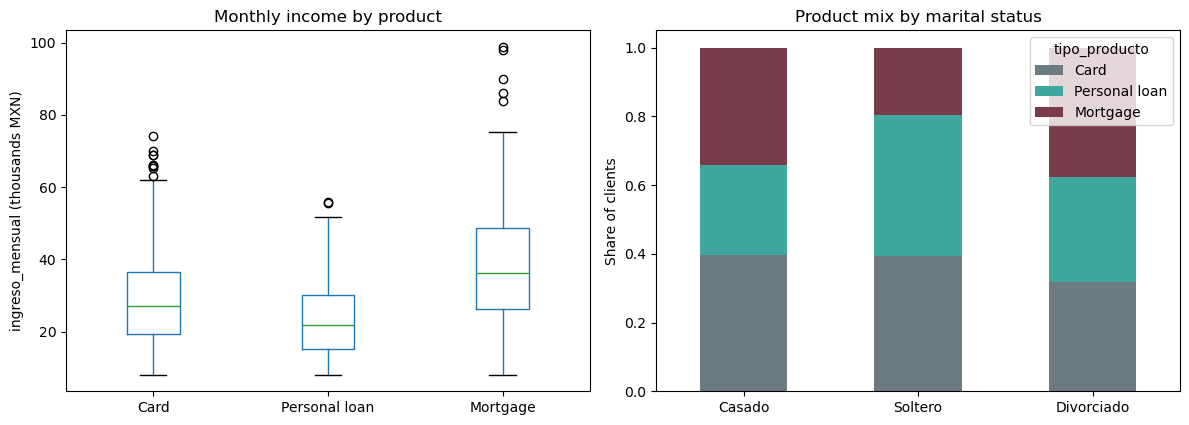

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

df.boxplot(column='ingreso_mensual', by='tipo_producto', ax=axes[0], grid=False)
axes[0].set_title('Monthly income by product')
axes[0].set_xlabel('')
axes[0].set_ylabel('ingreso_mensual (thousands MXN)')

mix = pd.crosstab(df['estado_civil'], df['tipo_producto'], normalize='index')[product_order]
mix.plot(kind='bar', stacked=True, ax=axes[1], color=['#6B7B7F', '#3FA7A0', '#7A3B4A'], rot=0)
axes[1].set_title('Product mix by marital status')
axes[1].set_xlabel('')
axes[1].set_ylabel('Share of clients')

plt.suptitle('')
plt.tight_layout()
plt.show()

**Interpretation:**
- **Income:** Mortgage clients earn the most (about $38k per month on average), Personal loan clients the least (about $23.5k), and Card clients sit in between (about $28.9k).
- **Marital status:** Single clients take Personal loans far more often (41%) and Mortgages far less often (19.5%) than Married clients (26% and 34%).

These are the patterns we expect the model to pick up.

### 6. Preparing Y and X

In [13]:
# Y as integer codes: Card = 0 (reference), Personal loan = 1, Mortgage = 2
y = df['tipo_producto'].cat.codes.astype(int)

# X: only the four predictors. `historial_pagos` is another response, so it stays out.
dummies = pd.get_dummies(df[['estado_civil']], drop_first=True, dtype=float)    # Casado is dropped = reference
X = pd.concat([df[['ingreso_mensual', 'edad_cliente', 'score_buro']], dummies], axis=1)
X = sm.add_constant(X)        # statsmodels does not add the intercept by itself

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f'Train: {len(X_train)}   Test: {len(X_test)}')
X_train.head()

Train: 800   Test: 200


,const,ingreso_mensual,edad_cliente,score_buro,estado_civil_Soltero,estado_civil_Divorciado
45,1.0,19.1,61,683,0.0,0.0
570,1.0,11.7,21,719,1.0,0.0
603,1.0,29.2,40,584,0.0,0.0
394,1.0,19.5,65,750,0.0,0.0
372,1.0,38.8,57,684,1.0,0.0


Passing the integer codes makes the reference explicit: **category 0 is the reference**. `stratify=y` keeps the product mix the same in train and test.

### 7. Fitting the Model

One call fits both equations (Personal loan vs. Card and Mortgage vs. Card) together.

In [14]:
model = sm.MNLogit(y_train, X_train)
result = model.fit(disp=False)
print(result.summary())

                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                  800
Model:                        MNLogit   Df Residuals:                      788
Method:                           MLE   Df Model:                           10
Date:                Thu, 08 Oct 2026   Pseudo R-squ.:                  0.1773
Time:                        15:45:57   Log-Likelihood:                -718.95
converged:                       True   LL-Null:                       -873.94
Covariance Type:            nonrobust   LLR p-value:                 1.208e-60
                    y=1       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                       7.1300      1.294      5.510      0.000       4.594       9.666
ingreso_mensual            -0.0388      0.008     -5.071      0.000      -0.054      -0.024


**How to read the summary:**  
It has **one block per non-reference category**, labelled with the response code (1 = Personal loan, 2 = Mortgage; both against Card).  
Each block is a full equation: an intercept (`const`) plus one coefficient for each predictor. Let's put the two blocks side by side and count them.

In [15]:
coef = result.params.copy()
coef.columns = ['Personal loan vs. Card', 'Mortgage vs. Card']
print(f'{coef.shape[0]} rows x {coef.shape[1]} columns = {coef.size} parameters')
coef.round(4)

6 rows x 2 columns = 12 parameters


,Personal loan vs. Card,Mortgage vs. Card
const,7.1300,-11.0594
ingreso_mensual,-0.0388,0.0617
edad_cliente,-0.0212,0.0508
score_buro,-0.0085,0.0096
estado_civil_Soltero,0.5631,-0.8449
estado_civil_Divorciado,0.3920,0.3226


12 parameters, exactly as predicted in Section 1. The reference category (Card) has no column: its coefficients are fixed at 0.

### 8. Interpreting the Coefficients

In [16]:
pvalues = result.pvalues.copy()
pvalues.columns = coef.columns

pd.concat({'log-odds (β)': coef, 'odds ratio exp(β)': np.exp(coef), 'p-value': pvalues}, axis=1).round(4)

log-odds (β)                    \
                        Personal loan vs. Card Mortgage vs. Card   
const                                   7.1300          -11.0594   
ingreso_mensual                        -0.0388            0.0617   
edad_cliente                           -0.0212            0.0508   
score_buro                             -0.0085            0.0096   
estado_civil_Soltero                    0.5631           -0.8449   
estado_civil_Divorciado                 0.3920            0.3226   

                             odds ratio exp(β)                    \
                        Personal loan vs. Card Mortgage vs. Card   
const                                1248.8675            0.0000   
ingreso_mensual                         0.9619            1.0637   
edad_cliente                            0.9790            1.0522   
score_buro                              0.9916            1.0096   
estado_civil_Soltero                    1.7562            0.4296   
estado_civil_Divorciado                 1.4799            1.3807   

                                       p-value                    
                        Personal loan vs. Card Mortgage vs. Card  
const                                   0.0000            0.0000  
ingreso_mensual                         0.0000            0.0000  
edad_cliente                            0.0033            0.0000  
score_buro                              0.0000            0.0000  
estado_civil_Soltero                    0.0034            0.0002  
estado_civil_Divorciado                 0.1745            0.2518

**Significance** works exactly as in the binary model: for each coefficient  
$$H₀: β = 0$$ against $$H₁: β ≠ 0$$
Tested with the Wald z-test; we reject H₀ when the p-value is below 0.05. Here `ingreso_mensual`, `edad_cliente`, `score_buro` and `estado_civil_Soltero` are significant in both columns, while `estado_civil_Divorciado` is not (p ≈ 0.17 and 0.25).

**Reading template:** *for each extra unit of X, the odds of [category k] instead of Card are multiplied by exp(β).* Each column is read on its own, always against Card.

In [17]:
for col in coef.columns:
    b = coef.loc['ingreso_mensual', col]
    print(f"{col}: +$1,000 of income multiplies the odds by {np.exp(b):.3f};  +$10,000 by {np.exp(10 * b):.3f}")
print()
for col in coef.columns:
    b = coef.loc['estado_civil_Soltero', col]
    print(f"{col}: Single (vs. Married) multiplies the odds by {np.exp(b):.3f}  ({(np.exp(b) - 1) * 100:+.0f}%)")

Personal loan vs. Card: +$1,000 of income multiplies the odds by 0.962;  +$10,000 by 0.678
Mortgage vs. Card: +$1,000 of income multiplies the odds by 1.064;  +$10,000 by 1.854

Personal loan vs. Card: Single (vs. Married) multiplies the odds by 1.756  (+76%)
Mortgage vs. Card: Single (vs. Married) multiplies the odds by 0.430  (-57%)


Each column compares one product with Card, and each coefficient is read holding the other predictors fixed. "Personal loan vs. Card" refers to the odds of choosing a Personal loan relative to a Card, P(Personal loan) / P(Card), and the odds ratio is the factor by which those odds change.

**Numeric predictor — `ingreso_mensual`:**

- *Personal loan vs. Card:*  
Each extra $1,000 of monthly income multiplies the odds of choosing a Personal loan relative to a Card by **0.962** (−3.8%).  
Higher income makes a client less likely to choose a Personal loan relative to a Card.  
Over +$10,000 of income, the odds are multiplied by 0.68.  

- *Mortgage vs. Card:*  
Each extra $1,000 multiplies the odds of choosing a Mortgage relative to a Card by **1.064** (+6.4%).  
Higher income makes a client more likely to choose a Mortgage relative to a Card.  
Over +$10,000, the odds are multiplied by 1.85.

**Categorical predictor — `estado_civil_Soltero`** (two references at once: Casado for the predictor, Card for the response):

- *Personal loan vs. Card:*   
Single clients, compared with Married clients, have **1.76×** the odds of choosing a Personal loan relative to a Card (+76%).  
They are more likely than Married clients to choose a Personal loan relative to a Card.

- *Mortgage vs. Card:*   
Single clients have **0.43×** the odds of choosing a Mortgage relative to a Card (−57%).  
They are less likely than Married clients to choose a Mortgage relative to a Card.

### 9. Checking Performance

In [18]:
proba = np.asarray(result.predict(X_test))          # one probability per category; each row adds up to 1
pd.DataFrame(proba[:5], columns=product_order).round(3)

,Card,Personal loan,Mortgage
0,0.467,0.459,0.075
1,0.477,0.435,0.088
2,0.105,0.009,0.887
3,0.456,0.185,0.359
4,0.337,0.632,0.031


Instead of one probability, the model returns **three per client**. The predicted product is the category with the highest probability (`argmax`).

In [19]:
pred = proba.argmax(axis=1)

cm = confusion_matrix(y_test, pred)
print(pd.DataFrame(cm, index=[f'Actual: {p}' for p in product_order],
                   columns=[f'Pred: {p}' for p in product_order]))
print()
print(classification_report(y_test, pred, target_names=product_order))

baseline = y_test.value_counts(normalize=True).max()
print(f'Accuracy: {accuracy_score(y_test, pred):.3f}   (baseline, always the most common product: {baseline:.3f})')
print(f'Macro AUC (one-vs-rest): {roc_auc_score(y_test, proba, multi_class="ovr"):.3f}')
print(f'McFadden pseudo R2: {result.prsquared:.3f}')

                       Pred: Card  Pred: Personal loan  Pred: Mortgage
Actual: Card                   42                   18              17
Actual: Personal loan          24                   36               4
Actual: Mortgage               22                    6              31

               precision    recall  f1-score   support

         Card       0.48      0.55      0.51        77
Personal loan       0.60      0.56      0.58        64
     Mortgage       0.60      0.53      0.56        59

     accuracy                           0.55       200
    macro avg       0.56      0.54      0.55       200
 weighted avg       0.55      0.55      0.55       200

Accuracy: 0.545   (baseline, always the most common product: 0.385)
Macro AUC (one-vs-rest): 0.724
McFadden pseudo R2: 0.177


**Interpretation:**
- **Confusion matrix (3×3):** read it by rows. Of the 77 Card clients in the test set, 42 were classified correctly, 18 were sent to Personal loan and 17 to Mortgage.
- **Accuracy 0.545 vs. a baseline of 0.385:** the model beats "always predict Card" by about 16 points.
- **Precision and recall are now computed per category.** The recall of each product is that product's sensitivity: of the clients who really took it, the share the model found. All three are around 0.53–0.56, so no product is being ignored.
- **Macro AUC ≈ 0.72:** the average, over the three products, of how well the model separates each product from the rest, without depending on any cutoff.
- **Pseudo-R² ≈ 0.18:** modest. Four predictors explain part of the choice, not all of it.

In a nominal model every mistake counts the same: confusing Card with Mortgage is no worse than confusing Card with Personal loan.

### 10. What Changes Compared with Binary Logistic Regression

| | Binary | Nominal |
|---|---|---|
| Response | 2 categories | K categories, no order |
| Equations | 1 | K − 1, each against the reference |
| Coefficients per predictor | 1 | K − 1 (one per column) |
| What `exp(β)` multiplies | odds of Y = 1 | odds of category k instead of the reference |
| What `predict` returns | 1 probability | K probabilities → `argmax` |
| Performance | 2×2 matrix, sensitivity / specificity, AUC | K×K matrix, precision and recall per category, macro AUC |